# Samuel — Final Regression: prediksi prioritas dengan struktur dan teks

**KASDAD TP2 · A06 KasdudLovers · SamuelIndriano · 2406400524 · final review individual**

Saya memprediksi `threat_rank`, indeks prioritas respons kerentanan pada skala 0–100.
Target berupa angka berurutan dengan jarak yang dievaluasi menggunakan **MAE**;
karena itu task ini menggunakan regresi. Kandidat yang dipertahankan adalah satu
LightGBM MAE dengan fitur terstruktur, TF-IDF/SVD32, serta rank blend dari inner validation.
Ini bukan stacking. Public Kaggle MAE **11,71363**, ref **57810150**; private score belum diketahui.

Notebook ini memperlihatkan alasan keputusan, bukan seluruh log eksperimen.
**Tiga sumber hasil dibedakan:** evaluasi W6 dihitung ulang dari data mentah;
perbandingan lintas-window berasal dari laporan eksperimen terverifikasi yang disimpan di Git;
hasil Kaggle merupakan evaluasi eksternal pada subset public. Tidak ada upload otomatis.

## 1. Lingkungan, data, dan batas penggunaan

Jalankan dari folder repository setelah memasang `requirements-research.txt`.
Bagian inti membutuhkan `data/raw/regression/Train.csv`; inference opsional memerlukan
Test dan SampleSubmission juga. Alternatif: atur
`TP2_DATA_DIR` ke folder induk yang berisi subfolder `regression/`.
Python 3.13.5 adalah lingkungan referensi; seed 42 dan dua thread membatasi variasi.
Tidak diperlukan cache eksperimen, kredensial, atau file sementara dari komputer penulis.

Semua fit imputasi, kategori, vocabulary/IDF, SVD, dan estimator hanya menggunakan
bagian training yang disebutkan. Test hanya digunakan pada tahap inference eksplisit.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'src/utils/paths.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'src/utils/paths.py').exists():
    raise FileNotFoundError('Jalankan notebook dari dalam repository tk2-kasdad.')
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.utils.paths import task_files
from src.models.regression_research_lgb_text import build_lgb_text
from src.models.classification_round2_models import stream_missing_mask
from src.models.round1_models import build_model as build_round1_model
from src.models.round1_evaluation import array_digest

get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white'})
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 5)
def read_report(path):
    return json.loads((ROOT / path).read_text(encoding='utf-8'))
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
print('Python:', platform.python_version(), '| seed: 42 | thread limit: 2')

Python: 3.13.5 | seed: 42 | thread limit: 2


In [2]:
files = task_files('regression')
if files['train'] is None: raise FileNotFoundError('Official Regression Train.csv diperlukan.')
assert sha(files['train']) == '756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10570e55ff6db0e0f082'
train = pd.read_csv(files['train'])
assert train.shape == (50608, 19) and train.record_id.is_unique
assert train.cycle_code.between(47, 79).all() and train.threat_rank.between(0, 100).all()
features = list(build_lgb_text().feature_names)
excluded = sorted(set(train.columns) - set(features) - {'threat_rank'})
display(pd.DataFrame({'bagian': ['Train', 'Test'], 'baris': [len(train), 29421],
                      'cycle': ['47–79', '80–91'], 'label tersedia': [True, False]}))
print('Predictor:', ', '.join(features))
print('Tidak dipakai sebagai predictor:', ', '.join(excluded))
display(train[features].isna().sum().rename('missing').to_frame().T)
display(train.threat_rank.describe(percentiles=[.05,.5,.95]).rename('threat_rank'))

,bagian,baris,cycle,label tersedia
0,Train,50608,47–79,True
1,Test,29421,80–91,False


Predictor: impact_load, entry_friction, cycle_code, scope_pressure, text_load, scope_trace, org_spread, module_spread, telemetry_flag, org_code, module_code, pattern_code, signal_stream
Tidak dipakai sebagai predictor: audit_lane, checksum_hint, pulse_a, pulse_b, record_id


,impact_load,entry_friction,cycle_code,scope_pressure,text_load,scope_trace,...,module_spread,telemetry_flag,org_code,module_code,pattern_code,signal_stream
missing,0,0,0,0,0,4232,...,4159,5703,2686,4044,8183,3404


count    50608.00000
mean        50.03260
std         28.86743
min          0.04280
5%           5.00960
50%         50.02815
95%         95.03406
max        100.00000
Name: threat_rank, dtype: float64

`impact_load` dan `entry_friction` adalah fitur resmi tambahan yang sebelumnya menjadi
target TP1; label/model/OOF TP1 tidak digabungkan. `signal_stream` adalah teks,
sedangkan `text_load` adalah ukuran numerik yang berbeda. ID dan field audit dikecualikan;
tidak ada target task lain pada allowlist. Source data dipertahankan utuh.
Format campuran dan missingness ditangani di pipeline, bukan dihapus diam-diam.
Keberadaan fitur dalam Test mendukung penggunaan pada coursework ini, tetapi belum
membuktikan kapan fitur tersebut tersedia dalam sistem operasional nyata.

## 2. EDA resmi Samuel dan konteks Regression

Pertanyaan EDA individual yang disetujui adalah: **Apakah proporsi `artifact_signal = 1` berbeda menurut ketersediaan `signal_stream`, dan bagaimana perbedaannya berubah setelah mempertimbangkan periode `cycle_code` serta volume narasi (`text_load`)?**

[Notebook EDA availability](12_samuel_formal_eda_availability.ipynb) menghitungnya dari official Classification Train. Secara marginal, artifact prevalence adalah 38,13% pada 3.404 baris missing dan 34,47% pada 47.204 baris present (gap +3,66 pp). Gap menjadi +3,96 pp setelah standardisasi exact cycle dan sekitar −2,2 pp setelah standardisasi periode × volume. Ini temuan deskriptif Classification, bukan bukti langsung manfaat teks untuk target Regression atau bukti sebab-akibat.

Untuk Regression, hipotesis bahwa teks melengkapi fitur structured diuji tersendiri pada `threat_rank`. Perbandingan text/structured di bawah memberi evidence prediktif terpisah; EDA Classification ini tidak dipakai untuk memilih recipe Regression. EDA temporal impact–threat terdahulu tetap menjadi [arsip riset](03_samuel_formal_eda.ipynb), bukan pertanyaan EDA resmi saat ini.

## 3. Perkembangan modeling dan alasan keputusan

MAE = rata-rata |prediksi − aktual|. Prediktor optimal secara kondisional adalah median;
itu menjelaskan baseline global/conditional median dan objective absolute error.
Median dapat mengecilkan variasi prediksi ketika conditional spread lebar: bias global
mendekati nol tidak menghapus overprediction pada target rendah dan underprediction pada target tinggi.

TP1 REG-Lite B memakai target dengan 80 nilai, top-10 mencakup 79,10% baris;
TP2 mempunyai 34.333 nilai dan top-10 hanya 1,08%. Pelajaran tentang median dan tail
tetap relevan, tetapi LightGBM multiclass per nilai target TP1 tidak disalin ke TP2.

Tabel ringkas berikut adalah **hasil historis**, bukan training ulang semua model.
Setiap baris menggunakan enam expanding windows yang sama: 47–55→56–59,
47–59→60–63, 47–63→64–67, 47–67→68–71, 47–71→72–75, 47–75→76–79.
Pooled MAE menimbang baris; equal-cycle menimbang setiap cycle secara sama.
H12_E = 47–55→56–67 dan H12_L = 47–67→68–79 memakai ulang 38.588 label primary,
sehingga **bukan replikasi independen**.

In [3]:
r1 = read_report('reports/round1/results.json')
model_names = {'R0_A': 'Global median', 'R0_B': 'Median impact', 'R0_C': 'Median impact × EF',
               'R1_A': 'Standardized OLS', 'R1_B': 'HGB squared error',
               'R1_C': 'HGB dua fitur, MAE', 'R1_D': 'HGB expanded, MAE'}
evolution = pd.DataFrame([{'pendekatan': model_names[k],
                          'primary MAE': r1['aggregate']['primary'][k]['raw']['mae'],
                          'H12 MAE': r1['aggregate']['secondary'][k]['raw']['mae']}
                          for k in model_names])
display(evolution.round(5))
research = pd.DataFrame(read_report('reports/regression_research/report_data.json')['comparison_records'])
selected = research[(research.Policy == 'inner') & research.Recipe.isin(
    ['structured_ridge', 'hybrid_ridge', 'svd_hgb', 'lgb_inner', 'lgb_text'])].copy()
display(selected[['Recipe', 'Primary MAE', 'Equal-cycle MAE', 'H12 MAE', 'H12_E', 'H12_L']].round(5))
# Committed aggregates only; this cell never opens experiment caches.
provenance_paths = ['reports/round1/results.json', 'reports/regression_round2/results.json',
                    'reports/regression_research/report_data.json', 'reports/regression_research/stage5_lgb_text.json']
provenance = {p: sha(ROOT/p) for p in provenance_paths}
print('Sumber tabel historis:', ', '.join(provenance_paths))

,pendekatan,primary MAE,H12 MAE
0,Global median,24.99995,24.99995
1,Median impact,15.56157,15.94048
2,Median impact × EF,15.31140,15.67423
3,Standardized OLS,15.62263,15.83498
4,HGB squared error,15.57102,15.89889
5,"HGB dua fitur, MAE",15.14899,15.47789
6,"HGB expanded, MAE",13.34984,15.57724


,Recipe,Primary MAE,Equal-cycle MAE,H12 MAE,H12_E,H12_L
31,hybrid_ridge,12.55130,12.79007,13.93812,16.39546,11.85908
35,svd_hgb,12.36618,12.67774,14.71412,17.27256,12.54955
39,lgb_inner,13.06489,13.32251,15.60415,17.88659,13.67310
45,structured_ridge,14.17865,14.33300,15.20582,17.22924,13.49390
47,lgb_text,11.93160,12.28355,14.70404,17.47326,12.36114


Sumber tabel historis: reports/round1/results.json, reports/regression_round2/results.json, reports/regression_research/report_data.json, reports/regression_research/stage5_lgb_text.json


**Mengapa langkah berikutnya dilakukan?** Conditional median melampaui global median,
tetapi linear global kurang menangkap heterogenitas. HGB absolute-error dua fitur
membaik; fitur expanded memberi primary gain lebih besar namun H12 awal memburuk.
Round 2 kemudian menghapus kelompok fitur dan membandingkan expanding/recent-8/recent-12
dengan sampel acak seukuran. Recent-8 expanded primary 13,21715 tetapi H12 15,79456;
menghapus codes memberi 14,07860/15,05347. Recency atau feature removal bukan solusi universal.

Pure percentile mapping juga merugikan kontrol HGB (R1-D primary 13,34984→13,84240).
Karena spacing saja tidak memperbaiki ranking inversions, penelitian beralih ke informasi teks.
Structured Ridge 14,17865/15,20582 menjadi hybrid Ridge 12,55131/13,93812 pada primary/H12;
pembanding satu keluarga ini menguatkan bukti manfaat content **dan availability** teks.
Text-only Ridge masih lemah. HGB+SVD32 kemudian membaik, dan LightGBM dengan representasi
sama memberi primary terbaik. Manfaat ini berasal dari kombinasi informasi dan estimator,
bukan sekadar mengganti algoritma.

[Round 1](../../reports/round1/ROUND1_FINDINGS.md),
[Round 2](../../reports/regression_round2/FINDINGS.md), dan
[research lengkap](../../reports/regression_research/COMPARISON_TABLES.md)
menyimpan semua eksperimen, termasuk hasil yang tidak menang.

,window,MAE,n
0,W1,16.40578,4114
1,W2,12.04287,6493
2,W3,12.35421,7078
3,W4,11.99939,4950
4,W5,10.77491,7462
5,W6,10.30343,8491
6,H12_E,17.47326,17685
7,H12_L,12.36114,20903


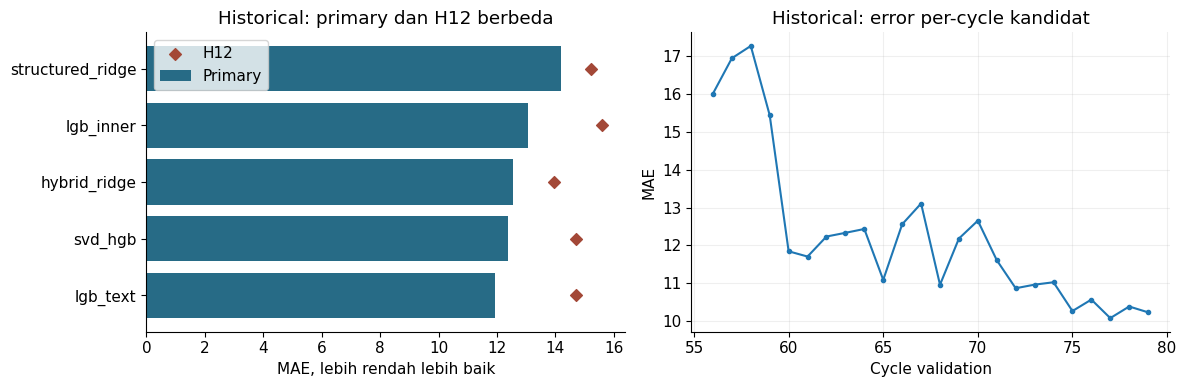

In [4]:
stage5 = read_report('reports/regression_research/stage5_lgb_text.json')
window_rows = []
for j in stage5['jobs']:
    if j['policy'] == 'inner':
        window_rows.append({'window': j['window'], 'MAE': j['raw']['mae'], 'n': j['raw']['n']})
windows = pd.DataFrame(window_rows)
display(windows.round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = selected.sort_values('Primary MAE')
axes[0].barh(order.Recipe, order['Primary MAE'], color='#276b86', label='Primary')
axes[0].scatter(order['H12 MAE'], order.Recipe, color='#a34837', marker='D', label='H12')
axes[0].set(title='Historical: primary dan H12 berbeda', xlabel='MAE, lebih rendah lebih baik'); axes[0].legend()
pc = pd.DataFrame(stage5['aggregate']['primary']['lgb_text__inner']['per_cycle'])
axes[1].plot(pc.cycle, pc.mae, '-o', markersize=3)
axes[1].set(title='Historical: error per-cycle kandidat', xlabel='Cycle validation', ylabel='MAE')
axes[1].grid(alpha=.2); fig.tight_layout(); plt.show()

## 4. Pipeline kandidat dan pemisahan temporal

1. Parser numerik/campuran menghasilkan nilai dan flag missing/approximate/suffix/parse-fail.
   Median dan pengelompokan rare category belajar pada fit fold saja.
   Ordinal category min-frequency 30/cap 254 memakai sentinel −1 untuk unknown/missing;
   LightGBM memperlakukan nilai kategori negatif sebagai missing.
2. `signal_stream` NaN atau string kosong setelah strip ditandai missing. TF-IDF word 1–2,
   min_df 2, maksimal 20.000 fitur, sublinear TF; vocabulary dan IDF hanya dari fit fold.
   TruncatedSVD randomized 32 komponen (n_iter 7, seed 42) memampatkan teks menjadi
   koordinat padat untuk pohon; ini bukan pemilihan 32 token atau embedding bahasa pralatih.
3. LightGBM `regression_l1`, 400 trees, learning rate 0,05. Hanya dua konfigurasi yang
   sebelumnya dibekukan: base (31 leaves/minleaf40/L2=1) dan regularized (15/80/3).
4. Pilih konfigurasi dan bobot rank {0;0,25;0,50;0,75;1} dengan inner temporal MAE.
   Rank dihitung dari **prediksi** dalam setiap supplied cycle, average ties:
   `clip((1−alpha)×raw + alpha×100×average_rank(raw)/n_cycle, 0, 100)`.

Rank mapping tidak memakai label inference, tetapi bersifat batch-dependent dan
memerlukan semua baris supplied cycle diprediksi bersama. Subset cycle dapat mengubah
hasil; kelengkapan terhadap universe sumber tidak diketahui. Mapping mengubah spacing,
bukan membetulkan inversi ranking.

### 4.1 Eksekusi nyata: inner sebelum W6

Untuk W6, model selection memakai **47–71→72–75**. Baru setelah keputusan dibekukan,
pipeline dilatih ulang pada **47–75** dan dievaluasi pada **76–79**.
Semua preprocessing dibangun ulang untuk setiap fit. Tidak ada early stopping dengan label outer/Test.

In [5]:
def rank_blend(raw, cycles, weight):
    frame = pd.DataFrame({'p': np.asarray(raw, float), 'c': np.asarray(cycles)})
    if not np.isfinite(frame.p).all() or frame.c.isna().any():
        raise ValueError('Prediksi dan cycle harus finite/lengkap.')
    percentile = (100 * frame.groupby('c').p.rank(method='average') /
                  frame.groupby('c').p.transform('size')).to_numpy()
    return np.clip((1-weight)*frame.p.to_numpy() + weight*percentile, 0, 100)

def fit_predict(params_id, fit_frame, predict_frame):
    model = build_lgb_text(params_id)
    with threadpool_limits(limits=2):
        model.fit(fit_frame[features], fit_frame.threat_rank.to_numpy())
        raw = model.predict(predict_frame[features])
    assert model.audit_state()['fit_rows'] == len(fit_frame)
    return model, raw

inner_train = train[train.cycle_code <= 71].copy()
inner_valid = train[train.cycle_code.between(72, 75)].copy()
outer_train = train[train.cycle_code <= 75].copy()
outer_valid = train[train.cycle_code.between(76, 79)].copy()
assert inner_train.cycle_code.max() < inner_valid.cycle_code.min()
assert outer_train.cycle_code.max() < outer_valid.cycle_code.min()
assert not set(outer_train.record_id) & set(outer_valid.record_id)
choices = []
start = time.perf_counter()
for param in ['base', 'regularized']:
    _, raw = fit_predict(param, inner_train, inner_valid)
    for alpha in [0., .25, .5, .75, 1.]:
        mapped = rank_blend(raw, inner_valid.cycle_code, alpha)
        choices.append({'param': param, 'rank_weight': alpha,
                        'MAE inner': mean_absolute_error(inner_valid.threat_rank, mapped)})
inner_choices = pd.DataFrame(choices).sort_values(['MAE inner', 'param', 'rank_weight'], kind='stable')
chosen = inner_choices.iloc[0]
display(inner_choices.reset_index(drop=True).round(6))
print('Keputusan W6 hanya dari inner:', chosen.param, float(chosen.rank_weight))

,param,rank_weight,MAE inner
0,base,0.50,10.73005
1,base,0.25,10.77491
2,base,0.75,10.77497
3,base,0.00,10.89544
4,base,1.00,10.91451
5,regularized,0.50,11.11519
6,regularized,0.25,11.15319
7,regularized,0.75,11.16510
8,regularized,0.00,11.27684
9,regularized,1.00,11.31529


Keputusan W6 hanya dari inner: base 0.5


In [6]:
outer_model, outer_raw = fit_predict(chosen.param, outer_train, outer_valid)
outer_prediction = rank_blend(outer_raw, outer_valid.cycle_code, float(chosen.rank_weight))
y_outer = outer_valid.threat_rank.to_numpy()
baseline_models = [
    {'id':'R0_A','kind':'global_median','features':'two'},
    {'id':'R0_C','kind':'joint_median','features':'two'}]
baseline_rows = []
for recipe in baseline_models:
    baseline = build_round1_model(recipe)
    names = [] if recipe['kind']=='global_median' else ['impact_load','entry_friction']
    with threadpool_limits(limits=2):
        baseline.fit(outer_train[names], outer_train.threat_rank.to_numpy())
        baseline_pred = baseline.predict(outer_valid[names])
    baseline_rows.append({'recipe':recipe['id'],'MAE W6':mean_absolute_error(y_outer,baseline_pred)})
display(pd.DataFrame(baseline_rows).round(5))
error = outer_prediction - y_outer
w6_metrics = {'n': len(y_outer), 'MAE': float(np.abs(error).mean()),
              'RMSE': float(np.sqrt(np.mean(error**2))), 'bias pred-actual': float(error.mean())}
expected_w6 = next(j for j in stage5['jobs'] if j['window'] == 'W6' and j['policy'] == 'inner')
assert np.isclose(w6_metrics['MAE'], expected_w6['raw']['mae'], rtol=0, atol=1e-8), 'Reproduksi W6 berbeda; selidiki environment/input.'
assert array_digest(outer_prediction) == expected_w6['prediction_sha256']
display(pd.DataFrame([w6_metrics], index=['Dihitung ulang: W6 76–79']))
core_receipt = {'task':'regression','fit_cycles':[47,75],'validation_cycles':[76,79],
    'fit_rows':len(outer_train),'validation_rows':len(outer_valid),'inner_choice':{
        'param':str(chosen.param),'rank_weight':float(chosen.rank_weight)},
    'metrics':w6_metrics,'prediction_sha256':array_digest(outer_prediction),
    'matches_historical_predictions':True,'historical_primary_mae':11.931600241417073,
    'historical_h12_mae':14.704040710404005,'kaggle_public_mae':11.71363,
    'fit_preprocessing_only_train':True,'test_used_in_core':False,'baseline_metrics':baseline_rows}
receipt_path = ROOT/'artifacts/samuel_final/regression_core_receipt.json'
receipt_path.parent.mkdir(parents=True,exist_ok=True)
receipt_path.write_text(json.dumps(core_receipt,indent=2)+'\n',encoding='utf-8')
w6_by_cycle = pd.DataFrame({'cycle': outer_valid.cycle_code.to_numpy(), 'abs_error': abs(error)}).groupby('cycle').agg(n=('abs_error','size'), MAE=('abs_error','mean'))
display(w6_by_cycle)
print('Equal-cycle W6:', w6_by_cycle.MAE.mean(), '| total detik training demonstrasi:', round(time.perf_counter()-start, 1))

,recipe,MAE W6
0,R0_A,25.00000
1,R0_C,14.96965


,n,MAE,RMSE,bias pred-actual
Dihitung ulang: W6 76–79,8491,10.30343,14.19391,-0.46194


,n,MAE
cycle,,
76,1822,10.57096
77,2335,10.08157
78,2146,10.38822
79,2188,10.23424


Equal-cycle W6: 10.31874648947231 | total detik training demonstrasi: 24.2


Nilai W6 di atas benar-benar dihitung ulang. Ia menguji **kebijakan inner selection**,
bukan fixed alpha 0,50 di setiap fold. Angka primary 11,93160 dan H12 14,70404 pada
tabel historis menggabungkan window lain yang tidak dilatih ulang di sini.
Mengulang W6 bukan holdout baru: semua cycle sudah dipakai EDA dan pengembangan adaptif.

## 5. Evaluasi error, pembanding, dan keterbatasan

LightGBM+text dipertahankan karena primary terbaik, membaik pada 6/6 primary windows
dan kedua H12 dibanding R1-D, dengan pipeline satu estimator. **Hybrid Ridge justru
lebih baik pada pooled H12** (13,93812 versus 14,70404), terutama H12_E.
Keputusan ini bukan klaim dominasi semua horizon; early H12 LightGBM 17,47326
tetap menjadi perhatian. Public 11,71363 mendukung benchmark eksternal tetapi
tidak menggantikan evaluasi temporal atau membuktikan private generalization.

,kelompok,n,MAE W6,bias W6
0,Semua,8491,10.30343,-0.46194
1,EF0,5738,11.49037,-1.12429
2,EF1,2753,7.82950,0.91857
3,Target ≤5,442,8.44707,8.17898
4,Target ≥95,434,5.97580,-5.34055
5,Stream missing,526,12.88477,3.97574
6,Stream present,7965,10.13296,-0.75500


,Recipe,Primary MAE,EF0,EF1,Low tail,High tail,Missing,Present
31,hybrid_ridge,12.5513,13.76768,10.02465,10.83168,9.55167,14.36961,12.42113
47,lgb_text,11.9316,12.97905,9.75585,12.23539,9.49544,13.04181,11.85212


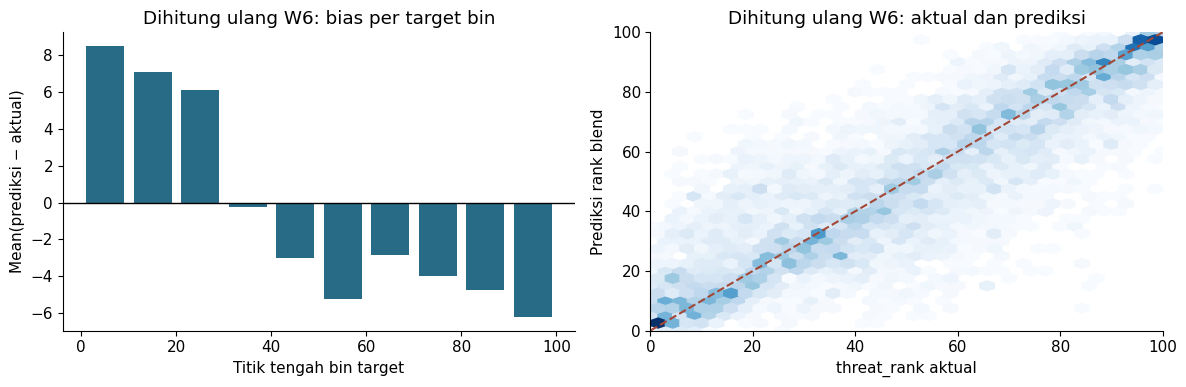

In [7]:
masks = {'Semua': np.ones(len(outer_valid), bool),
         'EF0': outer_valid.entry_friction.eq(0).to_numpy(),
         'EF1': outer_valid.entry_friction.eq(1).to_numpy(),
         'Target ≤5': y_outer <= 5, 'Target ≥95': y_outer >= 95,
         'Stream missing': stream_missing_mask(outer_valid),
         'Stream present': ~stream_missing_mask(outer_valid)}
fresh_subgroups = pd.DataFrame([{'kelompok': name, 'n': int(mask.sum()),
      'MAE W6': float(abs(error[mask]).mean()) if mask.any() else np.nan,
      'bias W6': float(error[mask].mean()) if mask.any() else np.nan}
      for name, mask in masks.items()])
display(fresh_subgroups.round(5))
display(selected[selected.Recipe.isin(['hybrid_ridge', 'lgb_text'])][
    ['Recipe', 'Primary MAE', 'EF0', 'EF1', 'Low tail', 'High tail', 'Missing', 'Present']].round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = pd.cut(y_outer, np.arange(0, 101, 10), include_lowest=True)
grouped = pd.DataFrame({'bin': bins, 'err': error}).groupby('bin', observed=True).err.mean()
axes[0].bar(np.arange(len(grouped))*10+5, grouped, width=8, color='#276b86')
axes[0].axhline(0, color='black', lw=1)
axes[0].set(title='Dihitung ulang W6: bias per target bin', xlabel='Titik tengah bin target', ylabel='Mean(prediksi − aktual)')
axes[1].hexbin(y_outer, outer_prediction, gridsize=35, mincnt=1, cmap='Blues')
axes[1].plot([0,100], [0,100], '--', color='#a34837')
axes[1].set(title='Dihitung ulang W6: aktual dan prediksi', xlabel='threat_rank aktual', ylabel='Prediksi rank blend', xlim=(0,100), ylim=(0,100))
fig.tight_layout(); plt.show()

Low/high-tail di primary historis masih memiliki signed bias +12,02207/−9,07956;
error kondisional ini dapat tertutup oleh bias global −0,41816. Kelompok target hanya
digunakan untuk evaluasi, bukan routing inference. Missing-stream lebih sulit pada
primary (13,04181 versus present 11,85212), tetapi urutannya terbalik pada H12;
tidak ada alasan menerapkan satu kesimpulan subgroup ke semua horizon.

Test memiliki 6.278/29.421 baris (21,34%) dengan sedikitnya satu scope/spread count nol,
tanpa analog nol di Train, dan pressure di bawah minimum Train. Nol tetap diparse sebagai
angka; makna genuine zero vs missing/source change belum diketahui. Unscored perturbation
bukan pengukuran error kelompok Test. Tidak ada label Test untuk memverifikasi risiko ini.
Inner selection menghindari fit pada outer labels, tetapi tidak menghapus adaptivitas
dari banyak round, pemilihan keluarga setelah melihat hasil, atau public feedback sebelumnya.

## 6. Refit seluruh Train dan inference resmi — tahap eksplisit

Evaluasi W6 telah selesai sebelum tahap ini. Untuk deployment recipe yang sudah disubmit,
inner 47–75→76–79 memilih **base dan alpha 0,50**, lalu seluruh 50.608 Train mempelajari
ulang pipeline. Memakai label 76–79 untuk deployment selection tidak mengubah nilai W6
yang sudah dilaporkan, tetapi label tersebut kini menjadi development data.

`RUN_FULL_TRAIN = True` menjalankan refit dan menghasilkan CSV lokal di
`artifacts/samuel_final/`; tahap ini membutuhkan tambahan waktu/memori dan tetap tanpa
Kaggle upload. Default False menjalankan demonstrasi temporal; aktifkan hanya untuk refit dan inference lokal.
File submission dan manifest historis tidak ditimpa. Tidak diperlukan CSV lama.

In [8]:
RUN_FULL_TRAIN = False
if RUN_FULL_TRAIN:
    assert files['test'] and files['sample'], 'Official Test dan SampleSubmission diperlukan untuk inference.'
    assert sha(files['test']) == '4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c'
    assert sha(files['sample']) == '63a51f4b7dfbb0eec9800099407abd8be14d25ec18a533cd39dc854ffc190a32'
    test = pd.read_csv(files['test']); sample = pd.read_csv(files['sample'])
    assert test.shape == (29421, 18) and 'threat_rank' not in test
    assert set(test.columns) == set(train.columns) - {'threat_rank'}
    assert test.record_id.is_unique and not set(train.record_id) & set(test.record_id)
    assert test.cycle_code.between(80, 91).all()
    assert sample.columns.tolist() == ['record_id','threat_rank'] and sample.record_id.equals(test.record_id)
    deployment_choices = []
    for param in ['base', 'regularized']:
        if param == chosen.param:
            raw = outer_raw
        else:
            _, raw = fit_predict(param, outer_train, outer_valid)
        for alpha in [0., .25, .5, .75, 1.]:
            p = rank_blend(raw, outer_valid.cycle_code, alpha)
            deployment_choices.append({'param': param, 'alpha': alpha,
                'mae': mean_absolute_error(y_outer, p)})
    deployment = sorted(deployment_choices, key=lambda d: (d['mae'], d['param'], d['alpha']))[0]
    assert deployment['param'] == 'base' and deployment['alpha'] == .5
    final_model, test_raw = fit_predict(deployment['param'], train, test)
    test_prediction = rank_blend(test_raw, test.cycle_code, deployment['alpha'])
    output = sample.copy()
    output['threat_rank'] = test_prediction
    assert len(output) == 29421 and output.record_id.is_unique
    assert output.record_id.equals(test.record_id) and np.isfinite(test_prediction).all()
    assert output.threat_rank.between(0, 100).all()
    destination = ROOT / 'artifacts/samuel_final/regression_reproduced.csv'
    destination.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes = output.to_csv(index=False, float_format='%.17g').encode('utf-8')
    if destination.exists() and destination.read_bytes() != csv_bytes:
        raise FileExistsError('Output sebelumnya berbeda; periksa sebelum mengganti file.')
    destination.write_bytes(csv_bytes)
    print('Refit:', final_model.audit_state()['fit_rows'], 'baris | CSV:', len(output), 'baris')
    print('Deployment:', deployment, '| SHA-256:', sha(destination))
    print('CSV lokal siap diperiksa; tidak ada upload otomatis.')
else:
    print('Refit/inference final belum dijalankan pada eksekusi ini. Aktifkan RUN_FULL_TRAIN jika diperlukan.')

Refit/inference final belum dijalankan pada eksekusi ini. Aktifkan RUN_FULL_TRAIN jika diperlukan.


## 7. Kesimpulan dan evidence

Kandidat Regression dipertahankan berdasarkan primary temporal evidence, perbandingan
lintas-window, dan error analysis. Text melengkapi struktur, dan LightGBM+SVD32
memperbaiki primary dengan satu estimator tanpa stacking. Hybrid Ridge tetap menjadi
counterexample H12. EDA A memberikan konteks karakteristik teks untuk Classification;
nilai tambah Regression berasal dari eksperimen terpisah, bukan dari asosiasi EDA itu.

Model dan submission yang dipertahankan: `lgb_text_inner_v1`, ref 57810150,
public MAE **11,71363**, baseline pengguna **12,23275** (selisih **0,51912**).
Private score, kelengkapan universe per-cycle, dan semantik novel zero belum diketahui.
Ini deliverable untuk final review Samuel, bukan pernyataan tugas kelompok siap dikumpulkan.

- [Manifest kandidat tersubmit](../../reports/regression_research/submissions/lgb_text_inner_v1.json)
- [Laporan pemilihan model](../../reports/samuel_final/MODEL_SELECTION.md)
- [Compliance resmi](../../docs/SAMUEL_FINAL_COMPLIANCE.md)
- [Reproduksi dan dependensi](../../docs/SAMUEL_FINAL_REPRODUCIBILITY.md)
- [Demo dan Q&A](../../docs/SAMUEL_DEMO.md)